# 예산 가드와 p95

**이 노트북에서 할 일**

1. 이 절에서 정한 토큰 수로 대화 스무 개의 대화당 비용을 셈하고, 평균과 95 백분위수를 봅니다.
2. 대화마다 먼저 예약하는 예산 가드로, 예약 금액을 평균으로 둔 실행 1을 합니다.
3. 예약 금액 하나만 95 백분위수로 바꾼 실행 2와 견주어, 받은 대화와 비용 합을 봅니다.

**준비물** — 이 노트북은 모델에 요청을 보내지 않고, API 키도 읽지 않습니다.
대화 스무 개의 토큰 수는 흐름을 보여 주려고 이 절에서 정한 값입니다.
비용은 그 토큰 수와 요금표(2026-09-29 확인)로 셈한 예상 비용이고, 청구 금액이 아닙니다.
실습 폴더의 도구 파일 `cost_tools.py`에서 함수 다섯을 가져옵니다.
따로 설치할 패키지는 없고, 이 노트북은 파일을 쓰지 않습니다.

모든 출력은 셀에 적은 값으로 정해져, 실행할 때마다 같습니다.
걸린 시간은 재지 않았습니다.

**기준 버전** — 이 노트북은 Python에 들어 있는 모듈과 도구 파일만 씁니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3절의 평균과 95 백분위수, 4절의 예산 가드를 보고 가설을 함께 세웁니다.
두 실행을 하는 5·6절과 두 실행을 견주는 7절은 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch34-cost-rate-limits`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 예산 make_budget 비용 상한 0.04 호출 한도 20과 초록 상자 대화 하나 예약 금액을 먼저 적음이 파란 상자 try_reserve 보내기 전에 예약으로 모입니다. 파란 상자에서 점선 둘이 갈라져, 노란 상자 예약됨 받은 대화와 노란 상자 비용 상한을 넘습니다 막힌 대화로 갑니다. 두 노란 상자 아래에는 회색 상자 받은 대화만 요청을 보냄 이 절은 모델 요청 없음과 회색 상자 막힌 대화는 요청을 보내지 않음 예약이 요청보다 먼저가 하나씩 이어지는 그림](attachment:05-1-보내기-전에-예약하는-예산-가드.png)

위에서 아래로 읽습니다.
초록 상자는 셀에 적은 예산 값과 대화이고, 파란 상자는 우리가 정의한 함수입니다.
점선 둘은 예약이 된 갈래와 막힌 갈래이고, 노란 상자는 노트북 4절에서 출력한 두 결과입니다.
맨 아래 회색 상자 둘은 코드 차례로 정해지는 사실이고, 이 절은 모델에 요청을 보내지 않습니다.
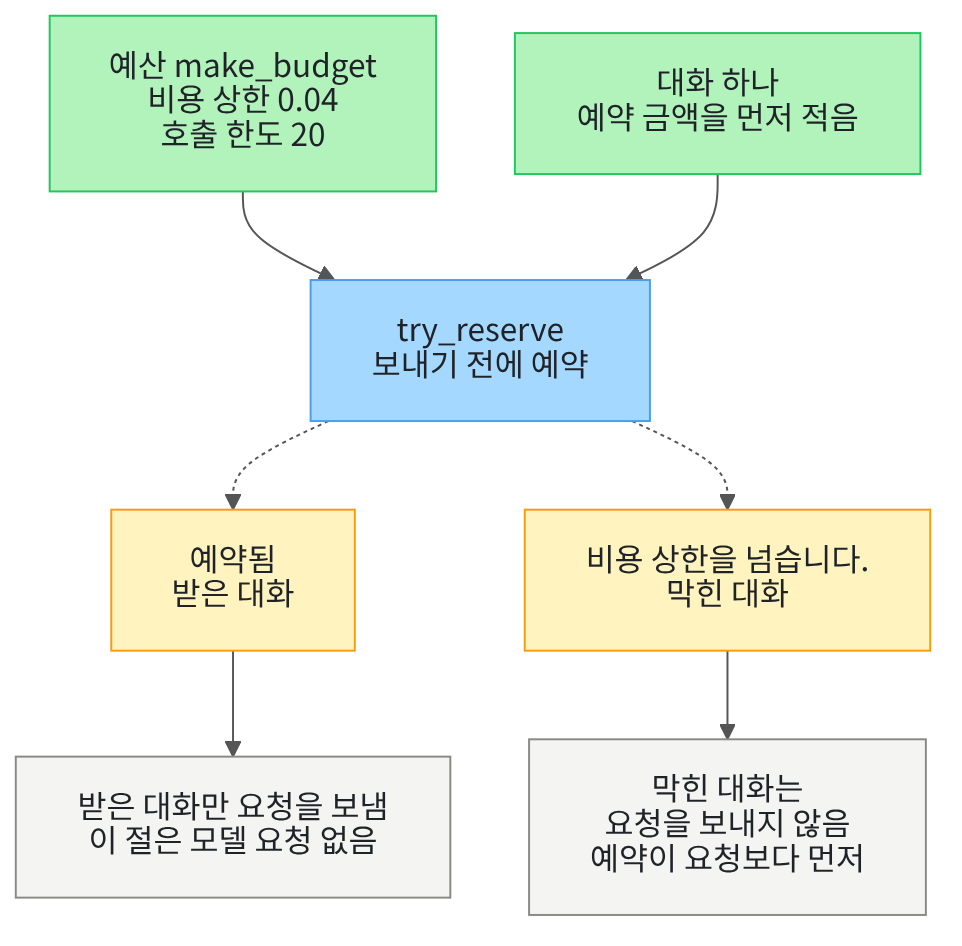

## 1. 준비

제목의 p95는 Ch 15 06절에서 본 95 백분위수를 줄여 쓴 말입니다.
이 절은 이 말을 제목에만 두고, 본문에서는 95 백분위수라고 씁니다.
제목의 예산 가드는 4절에서 풀어 씁니다.

첫 셀은 자리 계산에 쓸 모듈 `math`와 도구 파일의 함수 다섯을 가져옵니다.
따로 설치할 패키지가 없어, 설치 셀은 두지 않았습니다.

In [1]:
# 자리 계산에 쓸 모듈 math와, 도구 파일의 함수 다섯을 가져옵니다
import math
# Ch 6 06절·Ch 15 06절·Ch 16 04절에서 배운 함수는 도구 파일에서 가져옵니다
from cost_tools import estimate_cost, average, nearest_rank, make_budget, reserve

print("가져온 모듈:", math.__name__)
print("도구 파일에서 가져온 함수:", estimate_cost.__name__, average.__name__, nearest_rank.__name__)
print("도구 파일에서 가져온 함수:", make_budget.__name__, reserve.__name__)

가져온 모듈: math
도구 파일에서 가져온 함수: estimate_cost average nearest_rank
도구 파일에서 가져온 함수: make_budget reserve


**결과 읽기** — 출력 줄 `가져온 모듈: math`가 보입니다.
모듈 `math`는 Python에 들어 있어 따로 설치하지 않습니다.
함수 `estimate_cost`는 01~03절처럼 Ch 6 06절에서 배운 함수입니다.
함수 `average`·`nearest_rank`는 Ch 15 06절, `make_budget`·`reserve`는 Ch 16 04절에서 배웠습니다.
이 네 함수는 이 절에서 도구 파일에 옮겼습니다.

앞에서 배운 함수는 `cost_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

이 절은 모델 서비스에 요청을 보내지 않아, 키를 읽는 셀을 두지 않았습니다.

## 2. 대화 스무 개의 대화당 비용

Ch 15 06절은 대화 하나에서 보낸 요청들의 예상 비용을 모두 더해 대화당 비용이라고 불렀습니다.
이 절도 그 말을 씁니다.
이 절의 대화는 책 가게 상담 대화 스무 개이고, 모델에 보내지 않습니다.
대화마다 토큰 수를 정해 두고, 요금표로 대화당 비용을 셉니다.

다음 셀은 01절과 같은 요금표를 적습니다.

In [2]:
# gpt-5.4-mini의 공식 요금(100만 토큰당 달러)과 확인한 날짜를 적습니다
pricing_date = "2026-09-29"
mini_prices = {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}
print("요금 확인 날짜:", pricing_date)
print("mini 요금:", mini_prices)

요금 확인 날짜: 2026-09-29
mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}


**결과 읽기** — 출력 줄 `요금 확인 날짜: 2026-09-29`가 보입니다.
단위는 100만 토큰당 달러이고, 01·03절의 mini 요금표와 같습니다.
캐시 입력 요금 0.075달러는 일반 입력 요금 0.75달러의 10분의 1입니다.

다음 셀은 대화 스무 개의 토큰 수를 대화 차례대로 세 목록에 적습니다.
대화 하나의 토큰 수는 그 대화에서 보낸 요청들의 토큰 수를 더한 값으로 정했습니다.
세 목록은 입력 토큰 수, 그 가운데 캐시 입력 토큰 수, 출력 토큰 수입니다.
캐시 입력 토큰 수는 01절에서 본 것처럼 128의 배수로 정했습니다.

In [3]:
# 대화 스무 개의 토큰 수를 대화 차례대로 적습니다(흐름을 보여 주려고 이 절에서 정한 값입니다)
input_counts = [2600, 9400, 2400, 3000, 4200, 14000, 2500, 5200, 3100, 2600, 2400, 2100, 2900, 2800, 2300, 2700, 3300, 3000, 3500, 3600]
cached_counts = [1280, 5120, 1280, 1536, 2048, 7680, 1280, 2560, 1536, 1280, 1280, 1024, 1536, 1280, 1024, 1280, 1664, 1536, 1792, 1792]
output_counts = [240, 1100, 180, 320, 480, 1400, 220, 700, 280, 230, 200, 170, 300, 340, 190, 250, 340, 280, 360, 420]
print("대화 수:", len(input_counts))
print("대화 1의 입력·캐시 입력·출력 토큰 수:", input_counts[0], cached_counts[0], output_counts[0])

대화 수: 20
대화 1의 입력·캐시 입력·출력 토큰 수: 2600 1280 240


**결과 읽기** — 출력 줄 `대화 수: 20`이 보입니다.
대화 1은 입력 토큰 `2600`개 가운데 `1280`개가 캐시 입력이고, 출력 토큰은 `240`개입니다.
대화 2·6·8처럼 토큰 수가 큰 대화는, 요청을 여러 번 보낸 긴 대화로 정했습니다.
이 값은 실제로 잰 사용량이 아니라, 흐름을 보여 주려고 이 절에서 정한 목록입니다.

다음 셀은 토큰 수 셋으로, 응답의 사용량과 같은 모양의 딕셔너리를 만드는 함수를 정의합니다.
Ch 6 06절에서 본 `usage_metadata`와 키가 같아, 함수 `estimate_cost`에 그대로 넣을 수 있습니다.

In [4]:
# 입력·캐시 입력·출력 토큰 수로, 응답의 사용량(usage_metadata)과 같은 모양의 딕셔너리를 만듭니다
def make_usage(input_tokens, cached_tokens, output_tokens):
    details = {"cache_read": cached_tokens}
    usage = {"input_tokens": input_tokens, "output_tokens": output_tokens, "input_token_details": details}
    return usage

**결과 읽기** — 정의 셀이라 출력이 없습니다.
키 `input_token_details` 안의 `cache_read`가 캐시 입력 토큰 수입니다.
01절에서 본 사용량 딕셔너리와 같은 자리입니다.
함수는 새 딕셔너리를 내놓기만 하고, 모델을 부르지 않습니다.

다음 셀은 대화 1의 사용량 딕셔너리를 만들고, mini 요금표로 예상 비용을 셉니다.

In [5]:
# 대화 1의 사용량 딕셔너리를 만들어, mini 요금표로 예상 비용을 셈합니다
first_usage = make_usage(input_counts[0], cached_counts[0], output_counts[0])
first_cost = estimate_cost(first_usage, mini_prices["ordinary_input"], mini_prices["cached_input"], mini_prices["output"])
print("대화 1의 사용량:", first_usage)
print("대화 1의 예상 비용(달러):", round(first_cost, 6))

대화 1의 사용량: {'input_tokens': 2600, 'output_tokens': 240, 'input_token_details': {'cache_read': 1280}}
대화 1의 예상 비용(달러): 0.002166


**결과 읽기** — 출력 줄 `대화 1의 예상 비용(달러): 0.002166`이 보입니다.
일반 입력은 2600에서 1280을 뺀 1320토큰입니다.
셈은 (1320 × 0.75 + 1280 × 0.075 + 240 × 4.5) ÷ 1000000입니다.
990 + 96 + 1080 = 2166이라, 0.002166달러가 됩니다.

다음 셀은 대화 스무 개 모두에 같은 셈을 하고, 대화 차례대로 목록에 모읍니다.
값은 함수 `round`로 여섯째 자리에서 반올림합니다.

In [6]:
# 대화마다 사용량을 만들어 예상 비용을 셈하고, 여섯째 자리에서 반올림해 대화 차례대로 모읍니다
costs = []
for number in range(len(input_counts)):
    usage = make_usage(input_counts[number], cached_counts[number], output_counts[number])
    cost = estimate_cost(usage, mini_prices["ordinary_input"], mini_prices["cached_input"], mini_prices["output"])
    costs.append(round(cost, 6))
print("대화당 비용(달러):")
print(costs)

대화당 비용(달러):
[0.002166, 0.008544, 0.001746, 0.002653, 0.003928, 0.011616, 0.002001, 0.005322, 0.002548, 0.002121, 0.001836, 0.001649, 0.002488, 0.002766, 0.001889, 0.002286, 0.002882, 0.002473, 0.003035, 0.00338]


**결과 읽기** — 라벨 줄 아래 목록이 대화 스무 개의 대화당 비용입니다.
첫 값 `0.002166`은 앞 셀에서 셈한 대화 1의 값과 같습니다.
가장 큰 값은 여섯째 대화의 `0.011616`달러이고, 둘째 대화의 `0.008544`달러가 그다음입니다.
나머지 열여덟 개는 모두 0.006달러보다 작습니다.

## 3. 평균과 95 백분위수

Ch 15 06절은 대화당 비용을 줄 세워, 평균과 백분위수가 다르게 보이는 것을 봤습니다.
이 절은 그때 배운 두 함수를 도구 파일에서 가져와 씁니다.
함수 `average`는 값을 모두 더해 값의 수로 나누고, 여섯째 자리에서 반올림합니다.
다음 셀은 대화당 비용 스무 개의 평균을 셉니다.

In [7]:
# 대화당 비용 스무 개의 평균을 셉니다(여섯째 자리에서 반올림합니다)
cost_average = average(costs)
print("대화당 비용의 평균(달러):", cost_average)

대화당 비용의 평균(달러): 0.003366


**결과 읽기** — 출력 줄 `대화당 비용의 평균(달러): 0.003366`이 보입니다.
이 값은 목록에 있는 어느 대화의 비용과도 같지 않습니다.
평균은 비싼 대화 몇 개에 끌려 올라간 값입니다.

다음 셀은 같은 목록에서 95 백분위수를 찾습니다.
Ch 15 06절처럼 가장 가까운 자리 방식으로 셉니다.
자리는 95 × 값의 수 ÷ 100을 올린 정수이고, 작은 값부터 그 자리의 값을 고릅니다.

In [8]:
# 작은 값부터 줄 세운 목록에서 95 백분위수의 자리와 값을 보고, 가장 큰 값과 견줍니다
ordered = sorted(costs)
rank = math.ceil(95 * len(ordered) / 100)
cost_p95 = nearest_rank(costs, 95)
print("95 백분위수의 자리:", rank)
print("95 백분위수(달러):", cost_p95)
print("그 자리의 값과 같은가:", ordered[rank - 1] == cost_p95)
print("가장 큰 값(달러):", ordered[-1])

95 백분위수의 자리: 19
95 백분위수(달러): 0.008544
그 자리의 값과 같은가: True
가장 큰 값(달러): 0.011616


**결과 읽기** — 출력 줄 `95 백분위수의 자리: 19`와 `95 백분위수(달러): 0.008544`가 보입니다.
95 × 20 ÷ 100 = 19라, 작은 값부터 열아홉째 값을 골랐습니다.
가장 큰 값 `0.011616`은 스무째 값이라, 95 백분위수와 다릅니다.
출력 줄 `그 자리의 값과 같은가: True`로, 함수 `nearest_rank`가 같은 자리를 골랐다는 것을 봅니다.

다음 셀은 값 목록에서 기준 값보다 큰 값이 몇 개인지 세는 함수를 정의합니다.

In [9]:
# 값 목록에서 기준 값보다 큰 값이 몇 개인지 셉니다
def count_above(values, limit):
    count = 0
    for value in values:
        if value > limit:
            count = count + 1
    return count

**결과 읽기** — 정의 셀이라 출력이 없습니다.
기준 값과 같은 값은 세지 않고, 더 큰 값만 셉니다.
셀 바깥의 이름을 읽지 않고, 값 목록과 기준 값을 인자로 받습니다.

다음 셀은 대화 스무 개 가운데 평균보다 비싼 대화와, 95 백분위수보다 비싼 대화를 셉니다.

In [10]:
# 대화 스무 개 가운데 평균보다 비싼 대화와 95 백분위수보다 비싼 대화가 몇 개인지 셉니다
print("평균보다 비싼 대화 수:", count_above(costs, cost_average))
print("95 백분위수보다 비싼 대화 수:", count_above(costs, cost_p95))

평균보다 비싼 대화 수: 5
95 백분위수보다 비싼 대화 수: 1


**결과 읽기** — 출력 줄 `평균보다 비싼 대화 수: 5`와 `95 백분위수보다 비싼 대화 수: 1`이 보입니다.
평균보다 비싼 대화는 스무 개 가운데 다섯이었습니다.
95 백분위수보다 비싼 대화는 가장 큰 값인 여섯째 대화 하나뿐입니다.
가장 가까운 자리 방식에서 값이 스무 개이면, 95 백분위수보다 큰 값은 많아야 하나입니다.

## 4. 예산 가드와 예약 금액

예산 가드는 요청을 보내기 전에 예산에 예약해 보고, 막히면 보내지 않는 코드입니다.
택시를 타기 전에 지갑 속 남은 돈으로 갈 수 있는지 보고, 모자라면 타지 않는 것과 같습니다.
이 절 코드에서는 Ch 16 04절의 함수 `make_budget`과 `reserve`가 예산 가드입니다.
함수 `make_budget`은 호출 한도와 비용 상한을 담은 예산 딕셔너리를 만듭니다.
함수 `reserve`는 호출 한 번과 예상 비용을 예산에 적고, 한도나 상한을 넘으면 `ValueError`를 냅니다.

Ch 16 04절은 요청마다 예약했고, 요청 하나의 예상 비용을 0.002달러로 정해 두었습니다.
이 절은 대화 하나를 시작하기 전에 한 번 예약합니다.
대화 하나를 받기 전에 예산에 적는 예상 비용을 이 절에서는 예약 금액이라고 부릅니다.
모임 회비에서 한 사람 몫으로 미리 떼어 두는 돈과 같습니다.
이 절 코드에서는 변수 `run1_amount`와 `run2_amount`가 예약 금액입니다.

다음 셀은 대화당 비용 목록을 모두 더하는 함수를 정의합니다.

In [11]:
# 대화당 비용 목록을 모두 더하고, 여섯째 자리에서 반올림한 합을 내놓습니다
def total_cost(values):
    total = 0
    for value in values:
        total = total + value
    return round(total, 6)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
합도 대화당 비용처럼 여섯째 자리에서 반올림합니다.
작은 소수를 여러 번 더하면 끝자리에 아주 작은 차이가 남을 수 있기 때문입니다.

다음 셀은 대화 스무 개 모두에 쓸 비용 상한과 호출 한도를 정합니다.
스무 개를 모두 받을 때의 대화당 비용 합과도 견줍니다.

In [12]:
# 대화 스무 개 모두에 쓸 비용 상한과 호출 한도를 정하고, 스무 개를 모두 받을 때의 합과 견줍니다
cost_cap = 0.04
max_calls = len(costs)
all_total = total_cost(costs)
print("비용 상한(달러):", cost_cap)
print("호출 한도:", max_calls)
print("대화 스무 개의 대화당 비용 합(달러):", all_total)
print("모두 받으면 비용 상한을 넘는가:", all_total > cost_cap)

비용 상한(달러): 0.04
호출 한도: 20
대화 스무 개의 대화당 비용 합(달러): 0.067329
모두 받으면 비용 상한을 넘는가: True


**결과 읽기** — 출력 줄 `대화 스무 개의 대화당 비용 합(달러): 0.067329`와 `모두 받으면 비용 상한을 넘는가: True`가 보입니다.
비용 상한 `0.04`달러로는 대화 스무 개를 모두 받을 수 없습니다.
호출 한도는 대화 수와 같은 `20`으로 두었습니다.
대화마다 한 번 예약하므로, 이 절에서 호출 한도에 막히는 대화는 없습니다.
막는 일은 비용 상한만 합니다.

다음 셀은 예약을 해 보고, 막히면 받은 오류의 글을 내놓는 함수를 정의합니다.
Ch 16 04절처럼 `ValueError` 하나만 받아, 셀이 멈추지 않게 합니다.

In [13]:
# 예산에 예약 금액을 예약해 보고, 되면 「예약됨」을, 막히면 받은 ValueError의 글을 내놓습니다
def try_reserve(budget, amount):
    try:
        reserve(budget, amount)
    except ValueError as error:
        return str(error)
    return "예약됨"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `reserve`가 오류를 내지 않으면 글 「예약됨」을 내놓습니다.
오류를 내면 함수 `str`로 오류의 글을 꺼내 내놓습니다.
Ch 16 04절에서 본 대로, 막힌 예약은 예산 칸을 고치지 않습니다.

다음 셀은 예산 하나를 만들어 평균 금액을 한 번 예약해 봅니다.
이어서 남은 몫보다 큰 0.05달러도 예약해 봅니다.

In [14]:
# 예산 하나를 만들어 평균 금액을 한 번 예약해 보고, 남은 몫보다 큰 0.05달러도 예약해 봅니다
trial_budget = make_budget(max_calls, cost_cap)
too_large = 0.05
print("평균 금액 예약:", try_reserve(trial_budget, cost_average))
print("0.05달러 예약:", try_reserve(trial_budget, too_large))
print("예약 뒤 예산:", trial_budget)

평균 금액 예약: 예약됨
0.05달러 예약: 비용 상한을 넘습니다.
예약 뒤 예산: {'max_calls': 20, 'max_cost_usd': 0.04, 'calls': 1, 'cost_usd': 0.003366}


**결과 읽기** — 출력 줄 `평균 금액 예약: 예약됨`과 `0.05달러 예약: 비용 상한을 넘습니다.`가 보입니다.
둘째 예약은 `ValueError`로 막혔고, 함수는 그 오류의 글을 내놓았습니다.
출력 줄 `예약 뒤 예산:`에서 칸 `calls`는 `1`, 칸 `cost_usd`는 `0.003366`입니다.
막힌 둘째 예약은 두 칸을 바꾸지 않았습니다.

실제 서비스라면, 막힌 대화는 모델에 요청을 하나도 보내지 않습니다.
04절에서는 앱이 한 번 부른 호출에, 서버가 받은 요청이 아홉 번이었습니다.
예약은 앱이 세는 단위라, 받은 대화가 실제로 보내는 요청은 예약보다 많을 수 있습니다.

**가설** — 대화마다 예약 금액을 먼저 예약하고, 비용 상한에 걸리면 그 대화를 받지 않습니다.
예약 금액을 평균으로 잡으면, 95 백분위수로 잡을 때보다 받는 대화가 많을 것입니다.
그러나 평균보다 비싼 대화도 받게 되어, 받은 대화의 비용 합이 비용 상한을 넘을 수 있습니다.
95 백분위수로 잡으면 예약보다 비싼 대화는 드물겠지만, 막히는 대화가 많을 것입니다.

## 5. 실행 1 — 예약 금액은 평균

실행 1은 예약 금액을 3절의 평균으로 둡니다.
대화 스무 개가 대화 차례대로 들어온다고 보고, 들어올 때마다 예약해 봅니다.
예약이 된 대화를 이 절에서는 받은 대화라고 부르고, 예약이 막힌 대화는 막힌 대화라고 부릅니다.
정원이 찬 강의실에 들어간 사람과, 문 앞에서 돌아간 사람과 같습니다.
이 절 코드에서는 결과 목록의 `예약됨`이 받은 대화, `비용 상한을 넘습니다.`가 막힌 대화입니다.

실제 서비스는 지난 기록으로 정한 금액을 새 대화에 씁니다.
이 절은 같은 목록을 두 번 써서, 대화마다 예약 금액과 대화당 비용을 견줄 수 있게 했습니다.
다음 셀에서는 모델 요청이 나가지 않습니다.

In [15]:
# 실행 1: 예약 금액을 평균으로 두고, 대화 스무 개를 차례로 예약해 봅니다(모델 요청 없음)
run1_amount = cost_average
run1_budget = make_budget(max_calls, cost_cap)
run1_results = []
for number in range(len(costs)):
    run1_results.append(try_reserve(run1_budget, run1_amount))
print("예약 금액(달러):", run1_amount)
print("받은 대화 수:", run1_results.count("예약됨"))
print("막힌 대화 수:", run1_results.count("비용 상한을 넘습니다."))

예약 금액(달러): 0.003366
받은 대화 수: 11
막힌 대화 수: 9


**결과 읽기** — 출력 줄 `받은 대화 수: 11`과 `막힌 대화 수: 9`가 보입니다.
평균 0.003366달러를 열한 번 예약하면 0.037026달러이고, 열두 번이면 0.04달러를 넘습니다.
그래서 열한 대화를 받은 뒤부터는 모두 막혔습니다.
예약 금액이 모두 같아서, 한 번 막힌 뒤에는 뒤 대화도 모두 막힙니다.

다음 셀은 결과 목록에서 받은 대화의 대화당 비용만 모으는 함수를 정의합니다.

In [16]:
# 예약 결과 목록에서 「예약됨」인 대화의 대화당 비용만 대화 차례대로 모읍니다
def accepted_costs(results, costs):
    accepted = []
    for number in range(len(results)):
        if results[number] == "예약됨":
            accepted.append(costs[number])
    return accepted

**결과 읽기** — 정의 셀이라 출력이 없습니다.
결과 목록과 대화당 비용 목록은 같은 대화 차례라, 같은 번호끼리 짝지어 봅니다.
결과가 「예약됨」인 번호의 대화당 비용만 새 목록에 담습니다.

다음 셀은 실행 1에서 받은 대화의 대화당 비용을 모으고, 예약한 금액의 합과 견줍니다.
처음 막힌 대화의 번호도 봅니다.

In [17]:
# 실행 1에서 받은 대화의 대화당 비용을 모으고, 예약한 금액의 합과 받은 대화의 비용 합을 견줍니다
run1_accepted = accepted_costs(run1_results, costs)
run1_total = total_cost(run1_accepted)
# 메서드 index는 목록에서 그 값이 처음 나오는 자리를 0부터 세어 내놓습니다
print("처음 막힌 대화의 번호:", run1_results.index("비용 상한을 넘습니다.") + 1)
print("예약한 금액의 합(달러):", round(run1_budget["cost_usd"], 6))
print("받은 대화의 대화당 비용 합(달러):", run1_total)

처음 막힌 대화의 번호: 12
예약한 금액의 합(달러): 0.037026
받은 대화의 대화당 비용 합(달러): 0.044481


**결과 읽기** — 출력 줄 `예약한 금액의 합(달러): 0.037026`과 `받은 대화의 대화당 비용 합(달러): 0.044481`이 보입니다.
받은 대화는 대화 1부터 11까지이고, 출력 줄 `처음 막힌 대화의 번호: 12`와 맞습니다.
예약은 상한 안이었지만, 받은 대화의 비용을 모두 더하니 상한보다 컸습니다.
받은 대화 가운데 평균보다 비싼 대화가 들어 있었고, 특히 가장 비싼 대화 6이 받은 쪽에 있었기 때문입니다.

다음 셀은 받은 대화 가운데 예약보다 비싼 대화가 몇 개인지 셉니다.
대화당 비용이 예약 금액보다 큰 대화를 이 절에서는 예약보다 비싼 대화라고 부릅니다.
떼어 둔 식비보다 더 먹은 날과 같습니다.
이 절 코드에서는 함수 `count_above`에 받은 대화의 목록과 예약 금액을 넣어 셉니다.

In [18]:
# 실행 1에서 받은 대화 가운데 예약보다 비싼 대화 수와, 비용 합이 비용 상한을 넘는지 봅니다
run1_over = count_above(run1_accepted, run1_amount)
print("예약보다 비싼 대화 수:", run1_over)
print("대화당 비용 합이 비용 상한을 넘는가:", run1_total > cost_cap)

예약보다 비싼 대화 수: 4
대화당 비용 합이 비용 상한을 넘는가: True


**결과 읽기** — 출력 줄 `예약보다 비싼 대화 수: 4`와 `대화당 비용 합이 비용 상한을 넘는가: True`가 보입니다.
받은 열한 대화 가운데 넷이 예약 금액보다 비쌌습니다.
대화 2·5·6·8이고, 가장 비싼 대화 6도 받은 대화 쪽에 있었습니다.
예산 가드는 예약한 금액으로만 막으므로, 받은 대화의 비용 합은 비용 상한 0.04달러를 넘었습니다.

## 6. 실행 2 — 예약 금액 하나만 95 백분위수로

실행 2는 값 하나만 바꿉니다.
바꾸는 값은 예약 금액이고, 3절의 평균에서 95 백분위수로 올립니다.
대화 스무 개와 대화 차례, 비용 상한, 호출 한도는 실행 1과 같습니다.
예산은 새로 만들어, 실행 1에서 예약한 양이 섞이지 않게 합니다.

실행 전에 예상해 봅니다.
0.008544달러를 몇 번 예약하면 0.04달러를 넘을까요?

In [19]:
# 실행 2: 예약 금액 하나만 95 백분위수로 바꾸고, 같은 대화 스무 개를 새 예산으로 예약해 봅니다(모델 요청 없음)
run2_amount = cost_p95
run2_budget = make_budget(max_calls, cost_cap)
run2_results = []
for number in range(len(costs)):
    run2_results.append(try_reserve(run2_budget, run2_amount))
print("예약 금액(달러):", run2_amount)
print("받은 대화 수:", run2_results.count("예약됨"))
print("막힌 대화 수:", run2_results.count("비용 상한을 넘습니다."))

예약 금액(달러): 0.008544
받은 대화 수: 4
막힌 대화 수: 16


**결과 읽기** — 출력 줄 `받은 대화 수: 4`와 `막힌 대화 수: 16`이 보입니다.
0.008544달러를 네 번 예약하면 0.034176달러이고, 다섯 번이면 0.04달러를 넘습니다.
예약 금액을 올리자 받은 대화가 열하나에서 넷으로 줄었습니다.
예약 금액이 모두 같으면, 받는 대화 수는 비용 상한을 예약 금액으로 나눈 몫입니다.

다음 셀은 실행 2에서 받은 대화의 대화당 비용을 모으고, 예약한 금액의 합과 견줍니다.

In [20]:
# 실행 2에서 받은 대화의 대화당 비용을 모으고, 예약한 금액의 합과 받은 대화의 비용 합을 견줍니다
run2_accepted = accepted_costs(run2_results, costs)
run2_total = total_cost(run2_accepted)
print("처음 막힌 대화의 번호:", run2_results.index("비용 상한을 넘습니다.") + 1)
print("예약한 금액의 합(달러):", round(run2_budget["cost_usd"], 6))
print("받은 대화의 대화당 비용 합(달러):", run2_total)

처음 막힌 대화의 번호: 5
예약한 금액의 합(달러): 0.034176
받은 대화의 대화당 비용 합(달러): 0.015109


**결과 읽기** — 출력 줄 `처음 막힌 대화의 번호: 5`와 `받은 대화의 대화당 비용 합(달러): 0.015109`가 보입니다.
받은 대화는 대화 1부터 4까지입니다.
예약한 금액의 합은 0.034176달러였지만, 받은 대화의 비용은 그 절반보다 적었습니다.
남은 몫은 쓰이지 않은 채, 대화 열여섯을 막았습니다.

다음 셀은 실행 2에서 받은 대화 가운데 예약보다 비싼 대화를 셉니다.

In [21]:
# 실행 2에서 받은 대화 가운데 예약보다 비싼 대화 수와, 비용 합이 비용 상한을 넘는지 봅니다
run2_over = count_above(run2_accepted, run2_amount)
print("예약보다 비싼 대화 수:", run2_over)
print("대화당 비용 합이 비용 상한을 넘는가:", run2_total > cost_cap)

예약보다 비싼 대화 수: 0
대화당 비용 합이 비용 상한을 넘는가: False


**결과 읽기** — 출력 줄 `예약보다 비싼 대화 수: 0`과 `대화당 비용 합이 비용 상한을 넘는가: False`가 보입니다.
받은 네 대화는 모두 0.008544달러 이하였습니다.
대화 2는 95 백분위수와 같은 값이라, 예약보다 비싼 대화로 세지 않았습니다.
가장 비싼 대화 6은 막힌 대화 쪽이었습니다.
대화 6이 받은 대화 쪽에 있었다면, 예약보다 비싼 대화는 하나가 됩니다.

## 7. 두 실행 견주기

다음 셀은 두 실행의 결과를 한 표로 모읍니다.

In [22]:
# 두 실행의 결과를 한 표로 모읍니다(요청 없음)
run1_blocked = len(costs) - len(run1_accepted)
run2_blocked = len(costs) - len(run2_accepted)
print("실행 | 예약 금액(달러) | 받은 대화 | 막힌 대화 | 예약보다 비싼 대화 | 대화당 비용 합(달러) | 상한을 넘는가")
print("실행 1 |", run1_amount, "|", len(run1_accepted), "|", run1_blocked, "|", run1_over, "|", run1_total, "|", run1_total > cost_cap)
print("실행 2 |", run2_amount, "|", len(run2_accepted), "|", run2_blocked, "|", run2_over, "|", run2_total, "|", run2_total > cost_cap)

실행 | 예약 금액(달러) | 받은 대화 | 막힌 대화 | 예약보다 비싼 대화 | 대화당 비용 합(달러) | 상한을 넘는가
실행 1 | 0.003366 | 11 | 9 | 4 | 0.044481 | True
실행 2 | 0.008544 | 4 | 16 | 0 | 0.015109 | False


**결과 읽기** — 라벨 줄 아래 두 줄이 두 실행의 결과입니다.
첫 줄은 `실행 1 | 0.003366 | 11 | 9 | 4 | 0.044481 | True`입니다.
둘째 줄은 `실행 2 | 0.008544 | 4 | 16 | 0 | 0.015109 | False`입니다.
바꾼 것은 예약 금액 하나이고, 나머지 칸이 모두 달라졌습니다.

다음 셀은 두 실행마다 예약한 금액의 합에서, 받은 대화의 대화당 비용 합을 뺍니다.
뺀 값이 음수이면 예약보다 많이 쓴 것이고, 양수이면 예약해 두고 쓰지 않은 몫입니다.

In [23]:
# 두 실행마다 예약한 금액의 합에서 받은 대화의 대화당 비용 합을 뺍니다(요청 없음)
run1_gap = round(run1_budget["cost_usd"] - run1_total, 6)
run2_gap = round(run2_budget["cost_usd"] - run2_total, 6)
print("실행 1 예약 합에서 비용 합을 뺀 값(달러):", run1_gap)
print("실행 2 예약 합에서 비용 합을 뺀 값(달러):", run2_gap)

실행 1 예약 합에서 비용 합을 뺀 값(달러): -0.007455
실행 2 예약 합에서 비용 합을 뺀 값(달러): 0.019067


**결과 읽기** — 출력 줄 `실행 1 예약 합에서 비용 합을 뺀 값(달러): -0.007455`가 보입니다.
실행 1은 예약한 금액보다 0.007455달러를 더 썼습니다.
출력 줄 `실행 2 예약 합에서 비용 합을 뺀 값(달러): 0.019067`로, 실행 2는 그만큼을 예약만 하고 쓰지 않았습니다.
이 목록에서는 평균으로 예약하면 모자랐고, 95 백분위수로 예약하면 남는 몫이 컸습니다.

**결론** — 바꾼 값은 대화 하나의 예약 금액 하나였습니다.
평균으로 예약한 실행 1은 대화 열하나를 받았지만, 넷이 예약보다 비싸 비용 합이 상한을 넘었습니다.
95 백분위수로 예약한 실행 2는 넷만 받았고, 비용 합은 상한의 절반보다 적었습니다.
예약 금액을 올리면 상한을 넘을 걱정은 줄지만, 막히는 대화가 늘었습니다.

대화 차례는 두 실행의 차이가 보이도록 비싼 대화를 앞쪽에 둔 차례입니다.
값은 이 절에서 정한 토큰 수와 대화 차례로 정해지므로, 이 목록에서 본 결과로만 읽습니다.

## 정리

1. 예산 가드는 대화를 시작하기 전에 예약 금액을 예산에 적고, 비용 상한을 넘으면 그 대화를 받지 않습니다.
2. 예약 금액이 모두 같으면 받는 대화 수는 비용 상한을 예약 금액으로 나눈 몫이라, 금액을 올리면 같거나 줄어듭니다.
3. 예약은 예상 비용만 적으므로, 예약보다 비싼 대화를 받으면 비용 합이 비용 상한을 넘을 수 있습니다.

다음 06절은 이 챕터의 실습 절입니다. 01·03·05절에서 쓴 기능을 한 흐름으로 이어 봅니다.